<img src="https://fedesarrollo.org.co/logo-Fede.png" alt="Fedesarrollo" style="float: right; width: 300px; height: auto;">
<img src="https://upload.wikimedia.org/wikipedia/commons/f/f9/Logo_BID_Espa%C3%B1ol.png" alt="Banco Interamericano de Desarrollo" style="float: right; width: 220px; height: auto;">

# Descriptivos de los episodios de auge exportador

Editor: Juan Diego Heredia Niño - jheredia@fedesarrollo.org.co

Septiembre 2026

### Importar librerías

La siguiente celda marca el inicio de un nuevo bloque de trabajo independiente:

**Librerías utilizadas:**
- `pandas` y `numpy`: para manipulación y análisis de datos estructurados.
- `matplotlib.pyplot` y `seaborn`: para visualización de datos.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Configuración de rutas

Carga las rutas del proyecto y las opciones globales desde `config.py`, instalado como
paquete editable en la raíz del proyecto.

In [2]:
from config import raw, temp, figures

### Lectura de datos

Carga el panel de participaciones de mercado y la base de episodios identificados.

In [3]:
df_trade = pd.read_parquet(raw / 'modelo' / 'df_trade_share.parquet')
df_trade.head()

,anio,hs6_1996,nombre_o,o_iso3,region_o,ingreso_o,nombre_d,d_iso3,region_d,ingreso_d,valor_miles_usd,deflactor_2019,food_index,distancia,tipo_oportunidad,cultura_similaridad,total_prod_year,share
0,2004,620990,Thailand,THA,East Asia & Pacific,Upper middle income,Angola,AGO,Sub-Saharan Africa,Lower middle income,83.69,1.31,77.54,"9,947.91",Oportunidades a profundizar,43.80,635.11,0.13
1,2004,620990,Vietnam,VNM,East Asia & Pacific,Lower middle income,Angola,AGO,Sub-Saharan Africa,Lower middle income,77.22,1.31,77.54,"10,627.53",Oportunidades a profundizar,48.60,635.11,0.12
2,2004,621132,Brazil,BRA,BRA,Upper middle income,Angola,AGO,BRA,Lower middle income,212.80,1.31,77.54,"6,663.72",Oportunidades a profundizar,62.80,212.80,1.00
3,2004,621133,Portugal,PRT,Europe & Central Asia,High income,Angola,AGO,Sub-Saharan Africa,Lower middle income,581.76,1.31,77.54,"5,771.92",Oportunidades a profundizar,51.70,581.76,1.00
4,2004,621142,Brazil,BRA,BRA,Upper middle income,Angola,AGO,BRA,Lower middle income,67.07,1.31,77.54,"6,663.72",Oportunidades a profundizar,62.80,67.07,1.00


### Correspondencia de países con subregiones de Naciones Unidas

Define el diccionario de subregiones y la función que normaliza los nombres de país para
asignarles la suya.

In [4]:
# --- diccionario ONU (tal cual lo enviaste) -------------------------------
UN_SUBREGION = {
    # Africa
    "BFA": "Western Africa",
    "BEN": "Western Africa",
    "EGY": "Northern Africa",
    "MWI": "Eastern Africa",
    "ZAR": "Middle Africa",
    "ZMB": "Eastern Africa",
    "TUN": "Northern Africa",
    "CMR": "Middle Africa",
    "CIV": "Western Africa",
    "DZA": "Northern Africa",
    "BDI": "Eastern Africa",
    "GHA": "Western Africa",
    "LBR": "Western Africa",
    "TZA": "Eastern Africa",
    "CAF": "Middle Africa",
    "LBY": "Northern Africa",
    "MAR": "Northern Africa",
    "DJI": "Eastern Africa",
    "MUS": "Eastern Africa",
    "NGA": "Western Africa",
    "SWZ": "Southern Africa",
    "UGA": "Eastern Africa",
    "MDG": "Eastern Africa",
    "MLI": "Western Africa",
    "ZAF": "Southern Africa",
    "NAM": "Southern Africa",
    "ETH": "Eastern Africa",
    "NER": "Western Africa",
    "GIN": "Western Africa",
    "RWA": "Eastern Africa",
    "SLE": "Western Africa",
    "SYC": "Eastern Africa",
    "SEN": "Western Africa",
    "TGO": "Western Africa",
    "ZWE": "Eastern Africa",
    "MRT": "Western Africa",
    "COG": "Middle Africa",
    "KEN": "Eastern Africa",
    "BWA": "Southern Africa",
    "GAB": "Middle Africa",
    "ERI": "Eastern Africa",
    "LSO": "Southern Africa",
    "AGO": "Middle Africa",
    "MOZ": "Eastern Africa",
    "STP": "Middle Africa",      # São Tomé y Príncipe
    "COM": "Eastern Africa",
    "CPV": "Western Africa",
    "GMB": "Western Africa",
    "GNB": "Western Africa",
    "GNQ": "Middle Africa",   # Guinea Ecuatorial
    "SOM": "Eastern Africa",  # Somalia
    "TCD": "Middle Africa",   # Chad

    # Americas
    "GTM": "Central America",
    "ABW": "Caribbean",
    "ARG": "South America",
    "TUV": "Polynesia",
    "MEX": "Northern America",
    "CUB": "Caribbean",
    "ATG": "Caribbean",
    "BRB": "Caribbean",
    "DOM": "Caribbean",
    "HND": "Central America",
    "SUR": "South America",
    "CYM": "Caribbean",
    "TTO": "Caribbean",
    "BMU": "Northern America",
    "USA": "Northern America",
    "SLV": "Central America",
    "TCA": "Caribbean",
    "NIC": "Central America",
    "JAM": "Caribbean",
    "PAN": "Central America",
    "COL": "South America",
    "VEN": "South America",
    "ECU": "South America",
    "GUY": "South America",
    "PER": "South America",
    "PRY": "South America",
    "BRA": "South America",
    "BLZ": "Central America",
    "LCA": "Caribbean",
    "URY": "South America",
    "CHL": "South America",
    "BHS": "Caribbean",
    "CRI": "Central America",
    "BOL": "South America",
    "GRL": "Northern America",
    "CAN": "Northern America",
    "HTI": "Caribbean",
    "VCT": "Caribbean",          # San Vicente y las Granadinas
    "GRD": "Caribbean",          # Granada
    "DMA": "Caribbean",          # Dominica
    "KNA": "Caribbean",          # San Cristóbal y Nieves


    # Asia
    "KHM": "South-Eastern Asia",
    "KGZ": "Central Asia",
    "TMP": "South-Eastern Asia",
    "ARM": "Western Asia",
    "CHN": "Eastern Asia",
    "QAT": "Western Asia",
    "BRN": "South-Eastern Asia",
    "KWT": "Western Asia",
    "SAU": "Western Asia",
    "BTN": "Southern Asia",
    "LAO": "South-Eastern Asia",
    "VNM": "South-Eastern Asia",
    "JOR": "Western Asia",
    "MYS": "South-Eastern Asia",
    "MDV": "Southern Asia",
    "ISR": "Western Asia",
    "GEO": "Western Asia",
    "PNG": "Melanesia",
    "AFG": "Southern Asia",
    "BHR": "Western Asia",
    "YEM": "Western Asia",
    "KAZ": "Central Asia",
    "MAC": "Eastern Asia",
    "BGD": "Southern Asia",
    "ARE": "Western Asia",
    "OMN": "Western Asia",
    "TKM": "Central Asia",
    "HKG": "Eastern Asia",
    "MMR": "South-Eastern Asia",
    "IRN": "Southern Asia",
    "IND": "Southern Asia",
    "IDN": "South-Eastern Asia",
    "TUR": "Western Asia",
    "AZE": "Western Asia",
    "PHL": "South-Eastern Asia",
    "TJK": "Central Asia",
    "LBN": "Western Asia",
    "JPN": "Eastern Asia",
    "MNG": "Eastern Asia",
    "THA": "South-Eastern Asia",
    "SYR": "Western Asia",
    "UZB": "Central Asia",
    "PAK": "Southern Asia",
    "LKA": "Southern Asia",
    "IRQ": "Western Asia",
    "KOR": "Eastern Asia",
    "CYP": "Western Asia",
    "NPL": "Southern Asia",
    "SGP": "South-Eastern Asia",
    "PRK": "Eastern Asia",    # República Popular Democrática de Corea

    # Europe
    "ALB": "Southern Europe",
    "DNK": "Northern Europe",
    "CZE": "Eastern Europe",
    "CHE": "Western Europe",
    "FRA": "Western Europe",
    "DEU": "Western Europe",
    "MKD": "Southern Europe",
    "SVN": "Southern Europe",
    "LUX": "Western Europe",
    "BEL": "Western Europe",
    "BGR": "Eastern Europe",
    "POL": "Eastern Europe",
    "SVK": "Eastern Europe",
    "LTU": "Northern Europe",
    "ROM": "Eastern Europe",
    "EST": "Northern Europe",
    "ISL": "Northern Europe",
    "NLD": "Western Europe",
    "GRC": "Southern Europe",
    "HUN": "Eastern Europe",
    "HRV": "Southern Europe",
    "UKR": "Eastern Europe",
    "FIN": "Northern Europe",
    "FRO": "Northern Europe",
    "LVA": "Northern Europe",
    "BLR": "Eastern Europe",
    "MDA": "Eastern Europe",
    "ESP": "Southern Europe",
    "PRT": "Southern Europe",
    "SWE": "Northern Europe",
    "AND": "Southern Europe",
    "AUT": "Western Europe",
    "NOR": "Northern Europe",
    "MLT": "Southern Europe",
    "IRL": "Northern Europe",
    "GBR": "Northern Europe",
    "ITA": "Southern Europe",
    "BIH": "Southern Europe",

    # Oceania
    "AUS": "Australia and New Zealand",
    "NZL": "Australia and New Zealand",
    "FJI": "Melanesia",
    "NCL": "Melanesia",
    "SLB": "Melanesia",
    "FSM": "Micronesia",         # Estados Federados de Micronesia
    "KIR": "Micronesia",
    "PLW": "Micronesia",         # Palaos
    "VUT": "Melanesia",
    "PYF": "Polynesia",          # Polinesia Francesa
    "WSM": "Polynesia",          # Samoa
    "TON": "Polynesia",
}

# -------- función buscadora -----------------------------------------------
def get_subregion(iso_code: str, default=None) -> str | None:
    """
    Devuelve la sub-región ONU correspondiente al código ISO-3.
    
    Parameters
    ----------
    iso_code : str
        Código de país en formato ISO-3 (ej. 'COL', 'FRA').
    default : any, opcional
        Valor a devolver si el código no está en el diccionario.
        Por defecto devuelve `None`.
    
    Returns
    -------
    str | None
        Nombre de la sub-región o el valor de `default`.
    """
    return UN_SUBREGION.get(iso_code.upper(), default)

### Base de episodios

Carga los episodios identificados y construye las variables derivadas del análisis.

In [5]:
df_6 = pd.read_parquet(temp / 'exportaciones' / 'df_surge_vars_6.parquet')

df_6['Duración'] = (df_6['surge_end'] - df_6['surge_start']) + 1

df_6['Delta_x'] = df_6['x_end'] - df_6['x_start']

df_6['Delta_m'] = df_6['m_end'] - df_6['m_start']

df_6.drop(columns=['surge_end', 'x_start','x_end', 'm_start', 'm_end'], inplace=True)

df_6.query("Duración >= 3", inplace=True)

df_6.query("Delta_x > 0", inplace=True)

### Distribución de la duración de los episodios

Primera figura de la presentación: cuántos episodios se observan para cada duración en años.

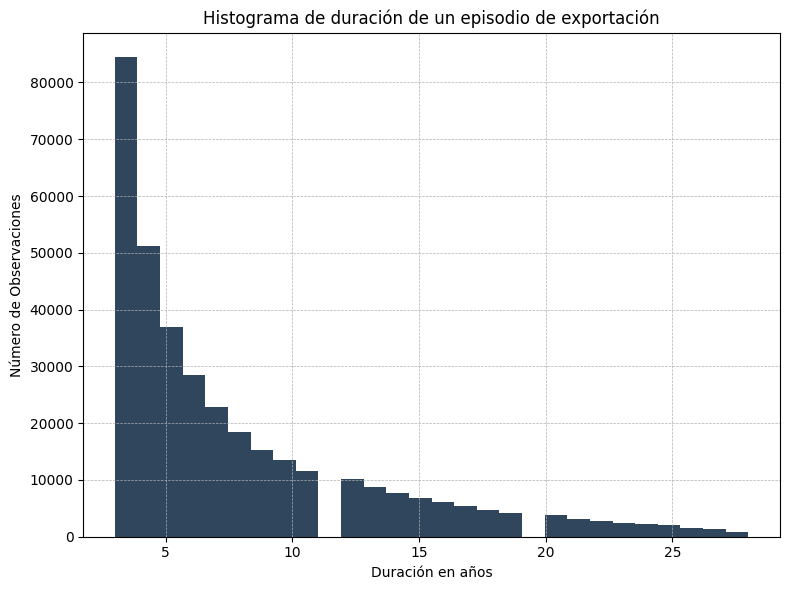

In [6]:
# Histograma de Duración en un solo gráfico y azul oscuro
fig, ax = plt.subplots(figsize=(8, 6))
ax.hist(df_6['Duración'], bins=28, color='#0a2540', alpha=0.85)  # azul oscuro
ax.set_title("Histograma de duración de un episodio de exportación")
ax.set_xlabel("Duración en años")
ax.set_ylabel("Número de Observaciones")
ax.grid(True, which="both", ls="--", linewidth=0.5)
plt.tight_layout()

# el original guardaba esta figura a mano desde la salida de celda
(figures / 'deck').mkdir(parents=True, exist_ok=True)
plt.savefig(figures / 'deck' / 'Image1.png')
plt.show()

### Crecimiento exportador por duración del episodio

Segunda figura de la presentación: el crecimiento promedio de las exportaciones aumenta con la
duración del episodio.

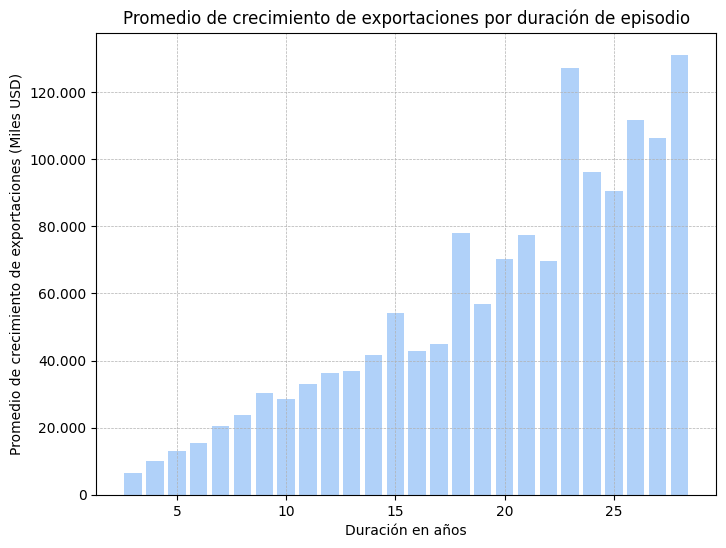

In [7]:
from matplotlib.ticker import FuncFormatter

# Agrupar por Duración y calcular el promedio
df_grouped = df_6.groupby('Duración', as_index=False)['Delta_x'].mean()

# Función para formatear los números con punto como separador de miles
def formatear_miles(x, pos):
    return f'{int(x):,}'.replace(',', '.')

# Crear gráfico
plt.figure(figsize=(8, 6))
plt.bar(df_grouped['Duración'], df_grouped['Delta_x'], color='#a3c9f9', alpha=0.85)  # azul pálido claro
plt.xlabel('Duración en años')
plt.ylabel('Promedio de crecimiento de exportaciones (Miles USD)')
plt.title('Promedio de crecimiento de exportaciones por duración de episodio')
plt.grid(True, which="both", ls="--", linewidth=0.5)

# Aplicar formato al eje Y
plt.gca().yaxis.set_major_formatter(FuncFormatter(formatear_miles))

# el original guardaba esta figura a mano desde la salida de celda
(figures / 'deck').mkdir(parents=True, exist_ok=True)
plt.savefig(figures / 'deck' / 'Image2.png')
plt.show()

### Clasificación industrial de los episodios

Adjunta a cada episodio la industria CIIU de su producto, en nomenclatura HS 1996.

In [8]:
df_ciiu = pd.read_parquet(temp / 'df_ciiu_1996.parquet')
df_ciiu = df_ciiu[['HS6','CIIU']].drop_duplicates()
df_ciiu['CIIU 3'] = df_ciiu['CIIU'].str[:3]
df_ciiu['CIIU 2'] = df_ciiu['CIIU'].str[:2]
df_ciiu['CIIU 1'] = df_ciiu['CIIU'].str[:1]
df_ciiu.rename(columns={'HS6': 'hs6_1996'}, inplace=True)
df_ciiu

,hs6_1996,CIIU,CIIU 3,CIIU 2,CIIU 1
0,010111,0142,014,01,0
1,010119,0142,014,01,0
2,010120,0142,014,01,0
3,010210,0141,014,01,0
4,010290,0141,014,01,0
...,...,...,...,...,...
5435,980610,3091,309,30,3
5436,980620,3091,309,30,3
5437,980690,3091,309,30,3
5438,980700,3030,303,30,3


In [9]:
df = (
    df_6
    .merge(df_trade[['o_iso3', 'd_iso3', 'cultura_similaridad']].drop_duplicates().reset_index(drop=True), on=['o_iso3', 'd_iso3'], how='left')
    .merge(df_trade[['o_iso3', 'd_iso3', 'distancia']].drop_duplicates().reset_index(drop=True), on=['o_iso3', 'd_iso3'], how='left')
    .merge(df_trade[['o_iso3', 'd_iso3', 'ingreso_o', 'ingreso_d']].drop_duplicates().reset_index(drop=True), on=['o_iso3', 'd_iso3'], how='left')
    .merge(df_ciiu[['hs6_1996', 'CIIU 3', 'CIIU 2','CIIU 1']].drop_duplicates().reset_index(drop=True), on='hs6_1996', how='left')
)

df['subregion_o'] = df['o_iso3'].map(get_subregion)
df['subregion_d'] = df['d_iso3'].map(get_subregion)
df

,o_iso3,d_iso3,hs6_1996,surge_start,share_start,Duración,Delta_x,Delta_m,cultura_similaridad,distancia,ingreso_o,ingreso_d,CIIU 3,CIIU 2,CIIU 1,subregion_o,subregion_d
0,ABW,BRA,271000,2000,0.01,5,"109,534.43","-2,378,000.50",55.05,"3,981.15",High income,Upper middle income,192,19,1,Caribbean,South America
1,ABW,CAN,271000,2004,0.01,3,"145,779.14","3,675,101.86",54.69,"3,697.97",High income,High income,192,19,1,Caribbean,Northern America
2,ABW,CRI,271000,2002,0.01,7,"577,586.17","1,097,940.59",68.06,"1,558.24",High income,Upper middle income,192,19,1,Caribbean,Central America
3,ABW,DOM,271000,2008,0.00,9,"66,707.52","-545,272.60",68.06,662.65,High income,Upper middle income,192,19,1,Caribbean,Caribbean
4,ABW,ESP,170199,2001,0.01,4,"3,889.43","45,938.49",52.64,"7,112.77",High income,High income,107,10,1,Caribbean,Southern Europe
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
356662,ZWE,ZMB,640399,2005,0.12,4,141.55,-58.84,82.80,398.72,Lower middle income,Lower middle income,152,15,1,Eastern Africa,Eastern Africa
356663,ZWE,ZMB,850710,1998,0.07,6,"2,527.77","3,026.28",82.80,398.72,Lower middle income,Lower middle income,272,27,2,Eastern Africa,Eastern Africa
356664,ZWE,ZMB,870422,1998,0.01,3,"1,659.23","-11,946.92",82.80,398.72,Lower middle income,Lower middle income,291,29,2,Eastern Africa,Eastern Africa
356665,ZWE,ZMB,940161,2003,0.17,4,692.02,521.25,82.80,398.72,Lower middle income,Lower middle income,311,31,3,Eastern Africa,Eastern Africa


### Agrupación de subregiones

Agrupa las subregiones de detalle en categorías más amplias, para que los efectos fijos de la
estimación tengan suficientes observaciones por categoría.

In [10]:
# África
df['subregion_d'] = np.where(df['subregion_d'].isin(['Western Africa', 'Middle Africa', 'Northern Africa', 'Eastern Africa', 'Southern Africa']), 'Africa', df['subregion_d'])

# Central America and Caribbean
df['subregion_d'] = np.where(df['subregion_d'].isin(['South America','Central America', 'Caribbean']), 'Latin America and Caribbean', df['subregion_d'])

# Other Asia and Oceania
df['subregion_d'] = np.where(df['subregion_d'].isin(['Southern Asia','Central Asia', 'Northern Asia', 'Australia and New Zealand', 'Melanesia', 'Micronesia', 'Polynesia']), 'Other Asia and Oceania', df['subregion_d'])


# África
df['subregion_o'] = np.where(df['subregion_o'].isin(['Western Africa', 'Middle Africa', 'Northern Africa', 'Eastern Africa', 'Southern Africa']), 'Africa', df['subregion_o'])

# Central America and Caribbean
df['subregion_o'] = np.where(df['subregion_o'].isin(['South America','Central America', 'Caribbean']), 'Latin America and Caribbean', df['subregion_o'])

# Other Asia and Oceania
df['subregion_o'] = np.where(df['subregion_o'].isin(['Southern Asia','Central Asia', 'Northern Asia', 'Australia and New Zealand', 'Melanesia', 'Micronesia', 'Polynesia']), 'Other Asia and Oceania', df['subregion_o'])

### Variable de control sectorial

Construye el control de industria a partir de los tres niveles de la CIIU. Conserva por
separado las siete clases con volumen suficiente y agrupa el resto en categorías residuales.

**Nota de auditoría:** las dos primeras asignaciones de `CIIU 3 control` quedan sobrescritas por
la tercera sin haberse usado. Se migran tal cual.

In [11]:
df['CIIU 3 control'] = df['CIIU 2'] + ' - ' + df['CIIU 3']
df['CIIU 3 control']

0         19 - 192
1         19 - 192
2         19 - 192
3         19 - 192
4         10 - 107
            ...   
356662    15 - 152
356663    27 - 272
356664    29 - 291
356665    31 - 311
356666    31 - 311
Name: CIIU 3 control, Length: 356667, dtype: object

In [12]:
df['CIIU 3 control'] = np.where(
    df['CIIU 3'].isin(['141','202','201','222','108','281','293']) == False, 
    df['CIIU 2'] + ' - ' + 'Otros',
    df['CIIU 2'] + ' - ' + df['CIIU 3']
)

In [13]:
df['CIIU 3 control'] = np.where(
    df['CIIU 3'].isin(['141','202','201','222','108','281','293']) == False, 
    np.where(
    df['CIIU 2'].isin(['27','26','10','24','25','29','01','31']) == False, # '21','23','28'
    df['CIIU 1'] + ' - ' + 'Otros',
    df['CIIU 2'] + ' - ' + 'Otros'
        ),
    df['CIIU 1'] + ' - ' + df['CIIU 3']
)

In [14]:
df['CIIU 3 control'] = np.where(
    df['CIIU 3 control'].isin(['31 - Otros','29 - Otros',  '0 - Otros', '5 - Otros']), 
    'Otras industrias',
    df['CIIU 3 control']
)

In [15]:
df['industria'] = df['CIIU 3 control']

In [16]:
df.drop(columns=['CIIU 3 control', 'ingreso_o', 'ingreso_d','CIIU 3', 'CIIU 2', 'CIIU 1'], inplace=True)

### Producto interno bruto de origen y destino

Incorpora el producto interno bruto per cápita de los países de origen y destino, deflactado a
precios constantes.

In [17]:
df_gdp = (
    pd.read_excel(raw / 'exportaciones' / 'gdp' / 'Emparejamiento_IMF_-_ISO.xlsx')
    .merge(
        pd.read_excel(raw / 'exportaciones' / 'gdp' / 'imf-dm-export-20250806.xls'),
        right_on="GDP, current prices (Billions of U.S. dollars)",
        left_on="nombre_imf")
    .drop(columns=["GDP, current prices (Billions of U.S. dollars)"])
    .melt(
        id_vars=["nombre_imf", "iso3"],   # Columnas que se mantienen fijas
        var_name="anio",                  # Nueva columna con los años
        value_name="gdp")                # Nombre de la columna con los valores
    .query("anio >= 1996 and anio <= 2023")
    .reset_index(drop=True)
    .drop(columns=["nombre_imf"])
    .merge(pd.read_parquet(temp / 'exportaciones' / 'deflactor.parquet'), on=["anio"], how="left")
)
df_gdp['gdp_deflactado'] = df_gdp['gdp'] * df_gdp['deflactor_2019'] * 1_000_000
df_gdp.drop(columns=['gdp','deflactor_2019'], inplace=True)
df_gdp.rename(columns={"gdp_deflactado": "gdp"}, inplace=True)
df_gdp

,iso3,anio,gdp
0,AFG,1996,NaN
1,ALB,1996,"4,939,380.81"
2,DZA,1996,"77,713,636.65"
3,AND,1996,NaN
4,AGO,1996,"16,032,394.17"
...,...,...,...
5399,VEN,2023,"87,060,976.78"
5400,VNM,2023,"368,228,209.77"
5401,YEM,2023,"16,507,884.40"
5402,ZMB,2023,"23,452,216.98"


In [18]:
df = (
    df
    .merge(
        df_gdp, 
        left_on=['o_iso3', 'surge_start'], 
        right_on=['iso3', 'anio'], 
        how='left')
    .drop(columns=['iso3', 'anio'])
    .merge(
        df_gdp, 
        left_on=['d_iso3', 'surge_start'], 
        right_on=['iso3', 'anio'], 
        how='left',
        suffixes=('_o', '_d'))
    .drop(columns=['iso3', 'anio'])
    )
df

,o_iso3,d_iso3,hs6_1996,surge_start,share_start,Duración,Delta_x,Delta_m,cultura_similaridad,distancia,subregion_o,subregion_d,industria,gdp_o,gdp_d
0,ABW,BRA,271000,2000,0.01,5,"109,534.43","-2,378,000.50",55.05,"3,981.15",Latin America and Caribbean,Latin America and Caribbean,1 - Otros,"2,678,074.73","937,188,893.03"
1,ABW,CAN,271000,2004,0.01,3,"145,779.14","3,675,101.86",54.69,"3,697.97",Latin America and Caribbean,Northern America,1 - Otros,"2,965,252.28","1,349,778,891.34"
2,ABW,CRI,271000,2002,0.01,7,"577,586.17","1,097,940.59",68.06,"1,558.24",Latin America and Caribbean,Latin America and Caribbean,1 - Otros,"2,701,467.87","22,834,425.62"
3,ABW,DOM,271000,2008,0.00,9,"66,707.52","-545,272.60",68.06,662.65,Latin America and Caribbean,Latin America and Caribbean,1 - Otros,"3,358,465.10","56,908,440.92"
4,ABW,ESP,170199,2001,0.01,4,"3,889.43","45,938.49",52.64,"7,112.77",Latin America and Caribbean,Southern Europe,10 - Otros,"2,651,115.89","877,836,766.30"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
359397,ZWE,ZMB,640399,2005,0.12,4,141.55,-58.84,82.80,398.72,Africa,Africa,1 - Otros,"11,532,004.14","10,619,133.50"
359398,ZWE,ZMB,850710,1998,0.07,6,"2,527.77","3,026.28",82.80,398.72,Africa,Africa,27 - Otros,"17,941,709.91","5,246,530.26"
359399,ZWE,ZMB,870422,1998,0.01,3,"1,659.23","-11,946.92",82.80,398.72,Africa,Africa,Otras industrias,"17,941,709.91","5,246,530.26"
359400,ZWE,ZMB,940161,2003,0.17,4,692.02,521.25,82.80,398.72,Africa,Africa,Otras industrias,"12,926,637.92","6,619,281.22"


### Base de estimación

Guarda el conjunto de variables con el que se estima el modelo de crecimiento exportador.

In [19]:
df[['o_iso3', 'd_iso3', 'hs6_1996','Delta_x', 'Delta_m','share_start', 'subregion_o','subregion_d','cultura_similaridad', 'distancia','industria', 'Duración', 'gdp_o', 'gdp_d']].to_parquet(temp / 'exportaciones' / 'df_para_estimacion.parquet', index=False)